# Exploratory Data Analysis — Raw Superstore Dataset

**Project:** Sales & Business Performance Analytics Dashboard  
**Branch:** `member-3/eda`  
**Dataset:** `data/raw/superstore_dataset2011-2015.csv`

## Objective
Explore the raw dataset before cleaning so that we can document its structure, quality issues, business patterns, and baseline KPIs. Later, the same key analyses can be repeated on the cleaned dataset for a fair before/after comparison.

## Important handling rules
- This notebook reads the raw CSV but does not overwrite or edit it.
- Any parsing and derived columns are created in memory.
- Do not automatically remove outliers or negative-profit records; investigate and document them first.
- Missing postal codes may be expected for some international records and should not trigger automatic row deletion.


## 1. Import libraries and configure display

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid")

# Run this notebook from the project root folder.
DATA_PATH = Path("data/raw/superstore_dataset2011-2015.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Open Jupyter from the repository root, "
        "or update DATA_PATH to the correct CSV location."
    )

print("Libraries loaded and dataset path found:", DATA_PATH)


FileNotFoundError: Could not find data\raw\superstore_dataset2011-2015.csv. Open Jupyter from the repository root, or update DATA_PATH to the correct CSV location.

In [3]:
import os

print("Current directory:", os.getcwd())
print("Files and folders:", os.listdir())


from pathlib import Path

DATA_PATH = Path(
    r"C:\Users\anshr\OneDrive\Desktop\sales-business-analytics\data\raw\superstore_dataset2011-2015.csv"
)

print("Dataset exists:", DATA_PATH.exists())

Current directory: c:\Users\anshr\OneDrive\Desktop\sales-business-analytics\notebooks
Files and folders: ['eda_raw_data.ipynb']
Dataset exists: True


In [6]:

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid")

# Find the project root from this notebook's working directory
cwd = Path.cwd()
if cwd.name == "notebooks":
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = cwd

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "superstore_dataset2011-2015.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

print("Project root:", PROJECT_ROOT)
print("Dataset:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())


Project root: c:\Users\anshr\OneDrive\Desktop\sales-business-analytics
Dataset: c:\Users\anshr\OneDrive\Desktop\sales-business-analytics\data\raw\superstore_dataset2011-2015.csv
Dataset exists: True


## 2. Load the raw dataset

The CSV is loaded into memory. We do not write anything back to the source file.

In [7]:
df_raw = pd.read_csv(DATA_PATH, encoding="cp1252")
df = df_raw.copy(deep=True)  # working copy for analysis; source CSV remains untouched

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
display(df.head())


Rows: 51,290
Columns: 24


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,Country,Postal Code,Market,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,42433,AG-2011-2040,1/1/2011,6/1/2011,Standard Class,TB-11280,Toby Braunhardt,Consumer,Constantine,Constantine,Algeria,NaN,Africa,Africa,OFF-TEN-10000025,Office Supplies,Storage,"Tenex Lockers, Blue",408.300,2,0.0,106.140,35.46,Medium
1,22253,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,JH-15985,Joseph Holt,Consumer,Wagga Wagga,New South Wales,Australia,NaN,APAC,Oceania,OFF-SU-10000618,Office Supplies,Supplies,"Acme Trimmer, High Speed",120.366,3,0.1,36.036,9.72,Medium
2,48883,HU-2011-1220,1/1/2011,5/1/2011,Second Class,AT-735,Annie Thurman,Consumer,Budapest,Budapest,Hungary,NaN,EMEA,EMEA,OFF-TEN-10001585,Office Supplies,Storage,"Tenex Box, Single Width",66.120,4,0.0,29.640,8.17,High
3,11731,IT-2011-3647632,1/1/2011,5/1/2011,Second Class,EM-14140,Eugene Moren,Home Office,Stockholm,Stockholm,Sweden,NaN,EU,North,OFF-PA-10001492,Office Supplies,Paper,"Enermax Note Cards, Premium",44.865,3,0.5,-26.055,4.82,High
4,22255,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,JH-15985,Joseph Holt,Consumer,Wagga Wagga,New South Wales,Australia,NaN,APAC,Oceania,FUR-FU-10003447,Furniture,Furnishings,"Eldon Light Bulb, Duo Pack",113.670,5,0.1,37.770,4.70,Medium


## 3. Understand the structure and data types

In [8]:
print("Column names:")
for column in df.columns:
    print("-", column)

print("\nData types and non-null counts:")
display(df.info())
display(df.describe(include="all").T)


Column names:
- Row ID
- Order ID
- Order Date
- Ship Date
- Ship Mode
- Customer ID
- Customer Name
- Segment
- City
- State
- Country
- Postal Code
- Market
- Region
- Product ID
- Category
- Sub-Category
- Product Name
- Sales
- Quantity
- Discount
- Profit
- Shipping Cost
- Order Priority

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          51290 non-null  int64  
 1   Order ID        51290 non-null  object 
 2   Order Date      51290 non-null  object 
 3   Ship Date       51290 non-null  object 
 4   Ship Mode       51290 non-null  object 
 5   Customer ID     51290 non-null  object 
 6   Customer Name   51290 non-null  object 
 7   Segment         51290 non-null  object 
 8   City            51290 non-null  object 
 9   State           51290 non-null  object 
 10  Country         512

None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,51290.0,NaN,NaN,NaN,25645.5,14806.29199,1.0,12823.25,25645.5,38467.75,51290.0
Order ID,51290,25035,CA-2014-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,51290,1430,18-06-2014,135,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,51290,1464,22-11-2014,130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,51290,4,Standard Class,30775,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,51290,1590,PO-18850,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,51290,795,Muhammed Yedwab,108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,51290,3,Consumer,26518,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,51290,3636,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,51290,1094,California,2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data-quality baseline

We will measure missingness, duplicate rows, duplicate IDs, and numeric/date parsing issues. These are observations for the report, not automatic cleaning instructions.

In [9]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)

display(missing_summary[missing_summary["missing_count"] > 0])
print("Exact duplicate rows:", int(df.duplicated().sum()))

for col in ["Row ID", "Order ID", "Customer ID", "Product ID"]:
    if col in df.columns:
        print(f"Unique values in {col}: {df[col].nunique(dropna=True):,}")

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
print("\nNumeric columns:", numeric_cols)
display(df[numeric_cols].describe().T)


,missing_count,missing_percent
Postal Code,41296,80.51


Exact duplicate rows: 0
Unique values in Row ID: 51,290
Unique values in Order ID: 25,035
Unique values in Customer ID: 1,590
Unique values in Product ID: 10,292

Numeric columns: ['Row ID', 'Postal Code', 'Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Cost']


,count,mean,std,min,25%,50%,75%,max
Row ID,51290.0,25645.500000,14806.291990,1.000,12823.250000,25645.500,38467.7500,51290.000
Postal Code,9994.0,55190.379428,32063.693350,1040.000,23223.000000,56430.500,90008.0000,99301.000
Sales,51290.0,246.490581,487.565361,0.444,30.758625,85.053,251.0532,22638.480
Quantity,51290.0,3.476545,2.278766,1.000,2.000000,3.000,5.0000,14.000
Discount,51290.0,0.142908,0.212280,0.000,0.000000,0.000,0.2000,0.850
Profit,51290.0,28.610982,174.340972,-6599.978,0.000000,9.240,36.8100,8399.976
Shipping Cost,51290.0,26.375915,57.296804,0.000,2.610000,7.790,24.4500,933.570


## 5. Investigate date columns

The source may contain more than one date format. We will try robust parsing and report how many values remain unparsed. Parsing here does not alter the raw CSV.

In [10]:
# Try flexible parsing first. If parsing results look suspicious, inspect examples below.
for col in ["Order Date", "Ship Date"]:
    parsed = pd.to_datetime(df[col], errors="coerce", format="mixed")
    df[col + " Parsed"] = parsed
    bad = parsed.isna() & df[col].notna()
    print(f"{col}: parsed {parsed.notna().sum():,} / {df[col].notna().sum():,}; unparsed non-null values: {bad.sum():,}")
    if bad.any():
        print("Examples that did not parse:")
        display(df.loc[bad, [col]].head(10))

display(df[["Order Date", "Order Date Parsed", "Ship Date", "Ship Date Parsed"]].head(10))


Order Date: parsed 51,290 / 51,290; unparsed non-null values: 0
Ship Date: parsed 51,290 / 51,290; unparsed non-null values: 0


,Order Date,Order Date Parsed,Ship Date,Ship Date Parsed
0,1/1/2011,2011-01-01,6/1/2011,2011-06-01
1,1/1/2011,2011-01-01,8/1/2011,2011-08-01
2,1/1/2011,2011-01-01,5/1/2011,2011-05-01
3,1/1/2011,2011-01-01,5/1/2011,2011-05-01
4,1/1/2011,2011-01-01,8/1/2011,2011-08-01
5,1/1/2011,2011-01-01,8/1/2011,2011-08-01
6,1/2/2011,2011-01-02,3/2/2011,2011-03-02
7,1/2/2011,2011-01-02,3/2/2011,2011-03-02
8,1/2/2011,2011-01-02,4/2/2011,2011-04-02
9,1/2/2011,2011-01-02,3/2/2011,2011-03-02


## 6. Numeric distributions and possible outliers

Boxplots and summary statistics help flag unusual values. A flagged value is not necessarily an error.

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Sales,51290.0,246.490581,487.565361,0.444,3.69000,8.80000,30.758625,85.053,251.0532,1015.95564,2301.00000,22638.480
Quantity,51290.0,3.476545,2.278766,1.000,1.00000,1.00000,2.000000,3.000,5.0000,8.00000,11.00000,14.000
Discount,51290.0,0.142908,0.212280,0.000,0.00000,0.00000,0.000000,0.000,0.2000,0.60000,0.70000,0.850
Profit,51290.0,28.610982,174.340972,-6599.978,-351.50565,-83.90475,0.000000,9.240,36.8100,211.50000,587.35995,8399.976
Shipping Cost,51290.0,26.375915,57.296804,0.000,0.20000,0.61000,2.610000,7.790,24.4500,111.40950,286.75430,933.570


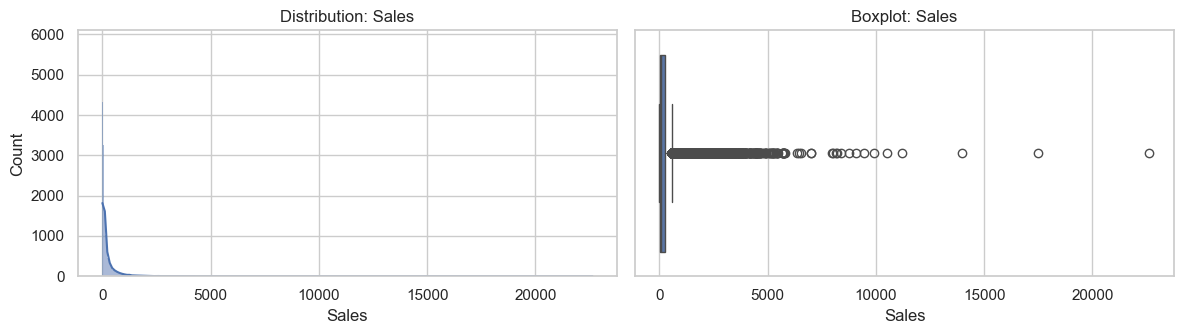

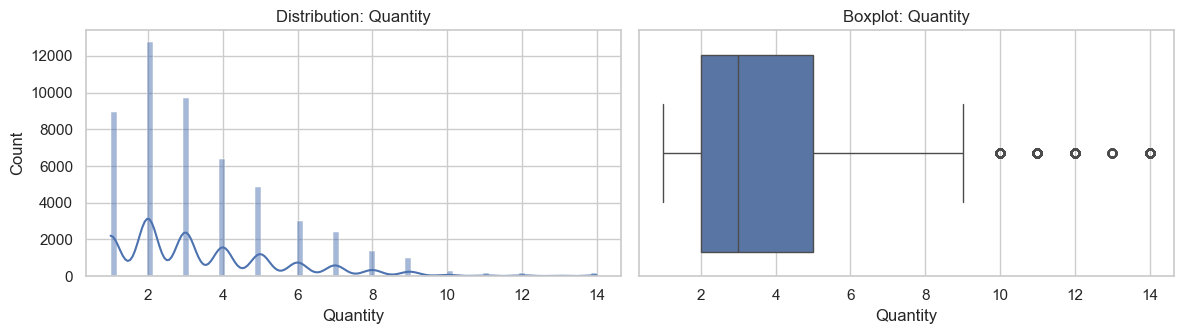

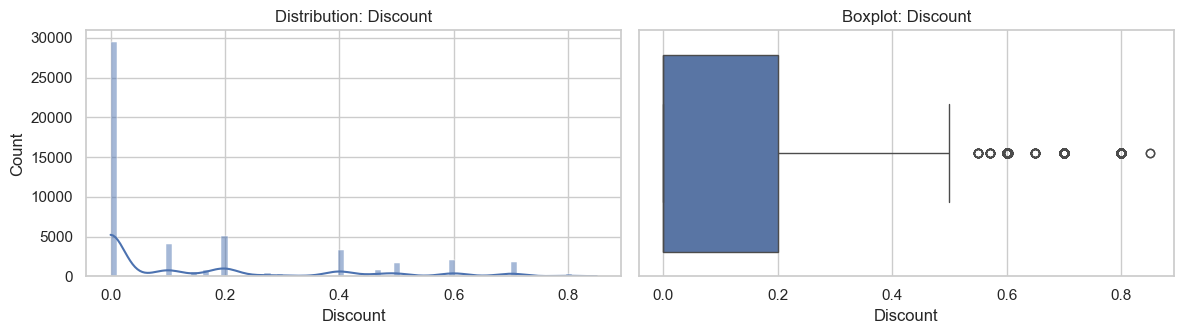

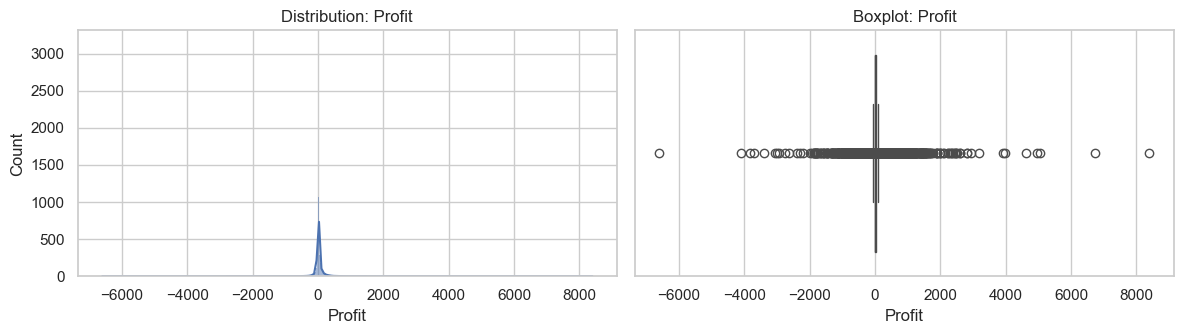

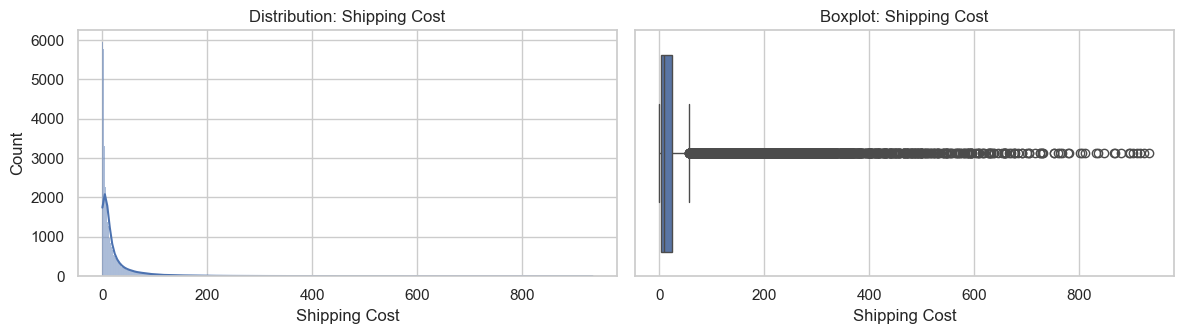

In [11]:
key_numeric = [c for c in ["Sales", "Quantity", "Discount", "Profit", "Shipping Cost"] if c in df.columns]
display(df[key_numeric].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T)

for col in key_numeric:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    sns.histplot(df[col].dropna(), kde=True, ax=axes[0])
    axes[0].set_title(f"Distribution: {col}")
    sns.boxplot(x=df[col], ax=axes[1])
    axes[1].set_title(f"Boxplot: {col}")
    plt.tight_layout()
    plt.show()


## 7. Baseline business KPIs

These are descriptive baseline metrics on the raw data. We will verify definitions with the team before using them in the final dashboard.

In [12]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
unique_orders = df["Order ID"].nunique()
unique_customers = df["Customer ID"].nunique()
aov = total_sales / unique_orders if unique_orders else np.nan
profit_margin = (total_profit / total_sales * 100) if total_sales else np.nan

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Sales", "Total Profit", "Total Quantity Sold",
        "Distinct Orders", "Distinct Customers",
        "Average Order Value (Sales / distinct orders)",
        "Profit Margin (Total Profit / Total Sales)"
    ],
    "Value": [
        total_sales, total_profit, total_quantity,
        unique_orders, unique_customers, aov, profit_margin
    ]
})
display(kpi_summary)


,Metric,Value
0,Total Sales,1.264250e+07
1,Total Profit,1.467457e+06
2,Total Quantity Sold,1.783120e+05
3,Distinct Orders,2.503500e+04
4,Distinct Customers,1.590000e+03
5,Average Order Value (Sales / distinct orders),5.049931e+02
6,Profit Margin (Total Profit / Total Sales),1.160733e+01


## 8. Sales and profit by category and sub-category

,Sales,Profit,Quantity,Orders,Profit Margin (%)
Category,,,,,
Technology,4.744557e+06,663778.73318,35176,8354,13.99
Furniture,4.110874e+06,285204.72380,34954,8195,6.94
Office Supplies,3.787070e+06,518473.83430,108182,19003,13.69


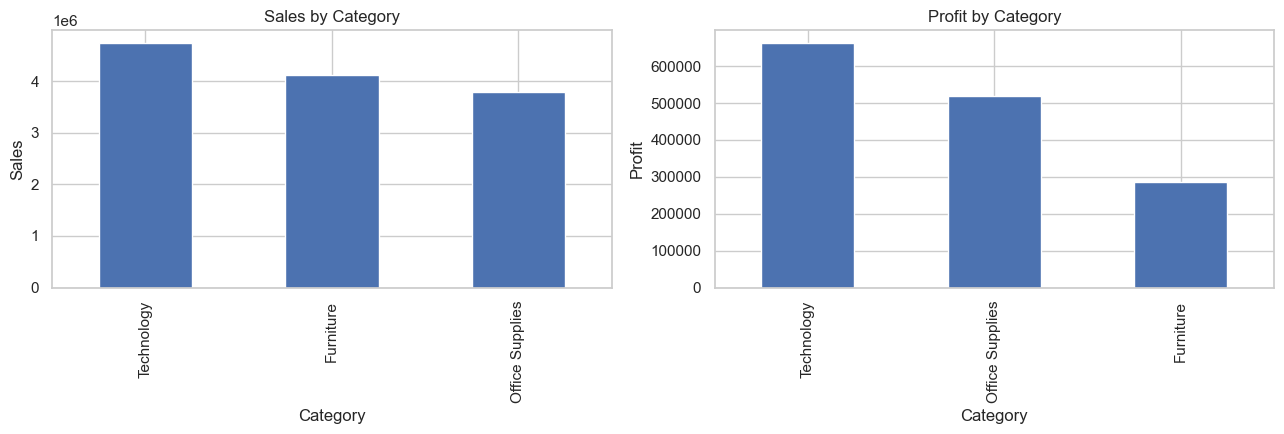

Sales        Profit  Orders
Category        Sub-Category                                    
Furniture       Tables        7.570419e+05  -64083.38870     836
Office Supplies Fasteners     8.324232e+04   11525.42410    2304
                Labels        7.340403e+04   15010.51200    2460
                Supplies      2.430742e+05   22583.26310    2281
                Envelopes     1.709043e+05   29601.11630    2310
Furniture       Furnishings   3.855783e+05   46967.42550    2965
Office Supplies Art           3.720920e+05   57953.91090    4366
Technology      Machines      7.790601e+05   58867.87300    1422
Office Supplies Paper         2.442917e+05   59207.68270    3234
                Binders       4.619115e+05   72449.84600    5392
                Storage       1.127086e+06  108461.48980    4534
Technology      Accessories   7.492370e+05  129626.30620    2889
Furniture       Chairs        1.501682e+06  140396.26750    3187
Office Supplies Appliances    1.011064e+06  141680.58940    1686
Furniture       Bookcases     1.466572e+06  161924.41950    2284
Technology      Phones        1.706824e+06  216717.00580    3133
                Copiers       1.509436e+06  258567.54818    2120

In [13]:
category_summary = (
    df.groupby("Category", dropna=False)
      .agg(Sales=("Sales", "sum"),
           Profit=("Profit", "sum"),
           Quantity=("Quantity", "sum"),
           Orders=("Order ID", "nunique"))
      .sort_values("Sales", ascending=False)
)
category_summary["Profit Margin (%)"] = (category_summary["Profit"] / category_summary["Sales"] * 100).round(2)
display(category_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
category_summary["Sales"].sort_values(ascending=False).plot(kind="bar", ax=axes[0], title="Sales by Category")
category_summary["Profit"].sort_values(ascending=False).plot(kind="bar", ax=axes[1], title="Profit by Category")
axes[0].set_ylabel("Sales")
axes[1].set_ylabel("Profit")
plt.tight_layout()
plt.show()

subcategory_summary = (
    df.groupby(["Category", "Sub-Category"], dropna=False)
      .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"))
      .sort_values("Profit")
)
display(subcategory_summary)


## 9. Regional and market performance

In [14]:
for dimension in ["Market", "Region", "Country", "Segment", "Ship Mode"]:
    if dimension in df.columns:
        summary = (
            df.groupby(dimension, dropna=False)
              .agg(Sales=("Sales", "sum"),
                   Profit=("Profit", "sum"),
                   Orders=("Order ID", "nunique"),
                   Customers=("Customer ID", "nunique"))
              .sort_values("Sales", ascending=False)
        )
        summary["Profit Margin (%)"] = (summary["Profit"] / summary["Sales"] * 100).round(2)
        print(f"Performance by {dimension}")
        display(summary.head(20))


Performance by Market


,Sales,Profit,Orders,Customers,Profit Margin (%)
Market,,,,,
APAC,3.585744e+06,436000.04900,5437,796,12.16
EU,2.938089e+06,372829.74150,4593,795,12.69
US,2.297201e+06,286397.02170,5009,793,12.47
LATAM,2.164605e+06,221643.48708,5138,794,10.24
EMEA,8.061613e+05,43897.97100,2462,760,5.45
Africa,7.837732e+05,88871.63100,2232,754,11.34
Canada,6.692817e+04,17817.39000,201,181,26.62


Performance by Region


,Sales,Profit,Orders,Customers,Profit Margin (%)
Region,,,,,
Central,2.822303e+06,311403.98164,5249,795,11.03
South,1.600907e+06,140355.76618,3270,776,8.77
North,1.248166e+06,194597.95252,2356,763,15.59
Oceania,1.100185e+06,120089.11200,1744,705,10.92
Southeast Asia,8.844232e+05,17852.32900,1517,672,2.02
North Asia,8.483098e+05,165578.42100,1150,617,19.52
EMEA,8.061613e+05,43897.97100,2462,760,5.45
Africa,7.837732e+05,88871.63100,2232,754,11.34
Central Asia,7.528266e+05,132480.18700,1026,570,17.60


Performance by Country


,Sales,Profit,Orders,Customers,Profit Margin (%)
Country,,,,,
United States,2.297201e+06,286397.02170,5009,793,12.47
Australia,9.252359e+05,103907.43300,1420,660,11.23
France,8.589311e+05,109029.00300,1222,679,12.69
China,7.005620e+05,150683.08500,925,549,21.51
Germany,6.288400e+05,107322.82050,907,582,17.07
Mexico,6.225906e+05,102818.09752,1329,670,16.51
India,5.896501e+05,129071.83500,785,494,21.89
United Kingdom,5.285763e+05,111900.15000,775,529,21.17
Indonesia,4.048875e+05,15608.67790,698,469,3.86


Performance by Segment


,Sales,Profit,Orders,Customers,Profit Margin (%)
Segment,,,,,
Consumer,6.507949e+06,749239.78206,13104,818,11.51
Corporate,3.824698e+06,441208.32866,7673,476,11.54
Home Office,2.309855e+06,277009.18056,4687,296,11.99


Performance by Ship Mode


,Sales,Profit,Orders,Customers,Profit Margin (%)
Ship Mode,,,,,
Standard Class,7.578652e+06,890596.02120,15154,1573,11.75
Second Class,2.565672e+06,292583.52708,5119,1374,11.40
First Class,1.830976e+06,208104.67520,3821,1243,11.37
Same Day,6.672020e+05,76173.06780,1347,820,11.42


## 10. Customer and product analysis

In [15]:
customer_summary = (
    df.groupby(["Customer ID", "Customer Name"], dropna=False)
      .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"))
      .sort_values("Sales", ascending=False)
)
print("Top 10 customers by sales")
display(customer_summary.head(10))

product_summary = (
    df.groupby(["Product ID", "Product Name", "Category", "Sub-Category"], dropna=False)
      .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Quantity=("Quantity", "sum"))
      .sort_values("Sales", ascending=False)
)
print("Top 10 products by sales")
display(product_summary.head(10))

print("10 products with lowest total profit (may include legitimate loss-making products)")
display(product_summary.sort_values("Profit").head(10))


Top 10 customers by sales


,,Sales,Profit,Orders
Customer ID,Customer Name,,,
TA-21385,Tom Ashbrook,35668.12080,6274.98910,25
GT-14710,Greg Tran,34471.89028,5164.84718,30
TC-20980,Tamara Chand,34218.26900,8787.47490,28
SM-20320,Sean Miller,31125.29496,-1083.67434,21
BW-11110,Bart Watters,30613.61650,3337.46590,35
HL-15040,Hunter Lopez,29664.23058,7657.50178,20
SE-20110,Sanjit Engle,29532.62502,5863.62392,36
PS-19045,Penelope Sewall,29252.31940,4426.19510,26
RB-19360,Raymond Buch,29197.63460,8523.95150,25


Top 10 products by sales


,,,,Sales,Profit,Quantity
Product ID,Product Name,Category,Sub-Category,,,
TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers,61599.8240,25199.9280,20
TEC-PH-10004664,"Nokia Smart Phone, with Caller ID",Technology,Phones,30041.5482,5455.9482,52
OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,Office Supplies,Binders,27453.3840,7753.0390,31
TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferencing Unit,Technology,Machines,22638.4800,-1811.0784,6
TEC-PH-10004823,"Nokia Smart Phone, Full Size",Technology,Phones,22262.1000,8121.4800,39
FUR-CH-10002024,HON 5400 Series Task Chairs for Big and Tall,Furniture,Chairs,21870.5760,0.0000,39
FUR-CH-10000027,"SAFCO Executive Leather Armchair, Black",Furniture,Chairs,21329.7300,1363.2300,50
OFF-AP-10004512,"Hoover Stove, Red",Office Supplies,Appliances,21147.0840,10345.5840,38
OFF-BI-10001359,GBC DocuBind TL300 Electric Binding System,Office Supplies,Binders,19823.4790,2233.5051,37


10 products with lowest total profit (may include legitimate loss-making products)


,,,,Sales,Profit,Quantity
Product ID,Product Name,Category,Sub-Category,,,
TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,Technology,Machines,11099.9630,-8879.9704,9
OFF-AP-10001623,"Hoover Stove, White",Office Supplies,Appliances,11728.8270,-4958.1630,31
TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,Technology,Machines,16829.9010,-4589.9730,18
TEC-PH-10002991,"Apple Smart Phone, Full Size",Technology,Phones,7259.1561,-4574.6439,20
TEC-MOT-10003050,"Motorola Smart Phone, Cordless",Technology,Phones,10348.7580,-3998.6820,24
TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,Technology,Machines,7999.9800,-3839.9904,4
FUR-CH-10001582,"Office Star Executive Leather Armchair, Black",Furniture,Chairs,6497.2770,-3066.7830,22
FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,Furniture,Tables,9917.6400,-2876.1156,27
FUR-TA-10002885,"Lesro Computer Table, Fully Assembled",Furniture,Tables,1199.3520,-2798.4880,14


## 11. Time trends

Only successfully parsed dates are used in this section. Review the parsing results above before interpreting trends.

,Sales,Profit,Orders
Order Month,,,
2011-01-01,138241.30042,13457.23302,297
2011-02-01,134969.94086,17588.83726,251
2011-03-01,171455.59372,16169.36062,337
2011-04-01,128833.47034,13405.46924,299
2011-05-01,148146.72092,14777.45792,288


,Sales,Profit,Orders
Order Month,,,
2014-08-01,432731.04194,46443.47934,799
2014-09-01,405436.70584,52533.83284,846
2014-10-01,406659.41500,52342.49740,847
2014-11-01,508954.73156,55561.72406,978
2014-12-01,427757.39800,48920.76000,931


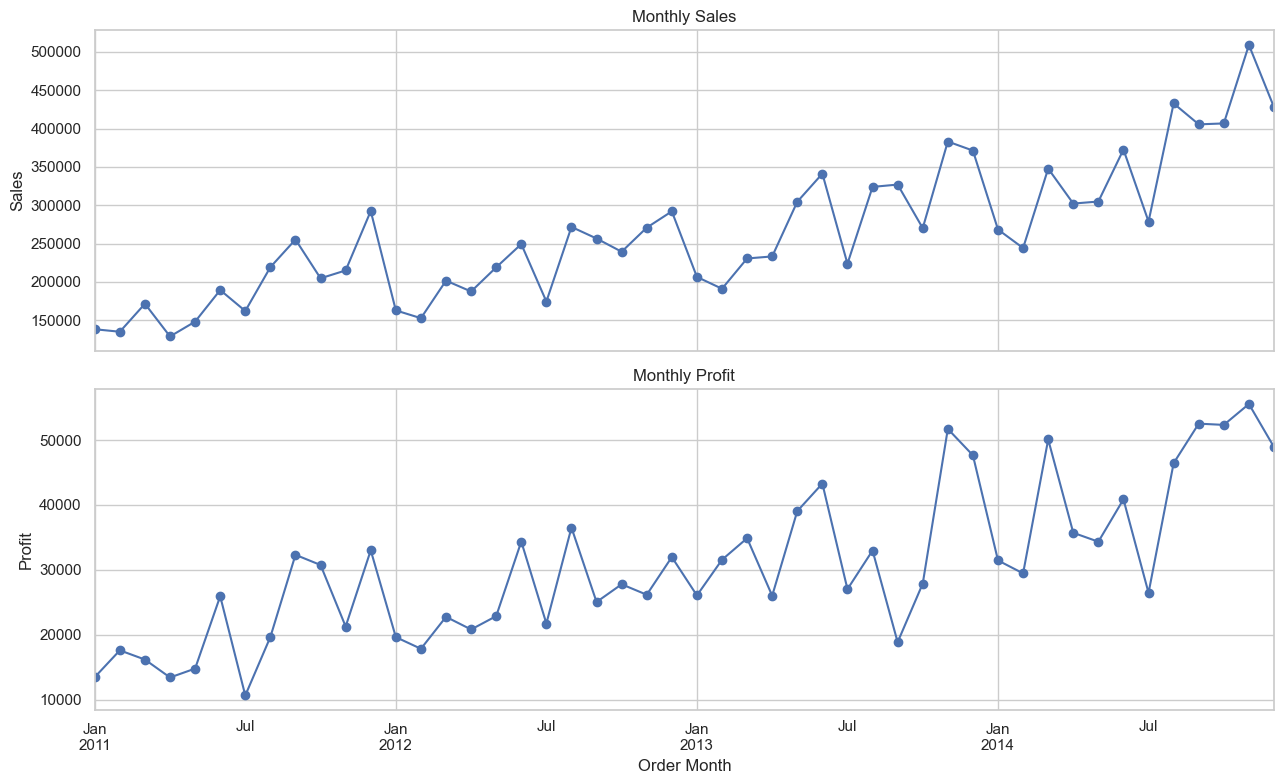

,Sales,Profit,Orders
Order Date Parsed,,,
2011,2.259451e+06,248940.81154,4440
2012,2.677439e+06,307415.27910,5343
2013,3.405746e+06,406935.23018,6721
2014,4.299866e+06,504165.97046,8531


In [16]:
dated = df.dropna(subset=["Order Date Parsed"]).copy()
dated["Order Month"] = dated["Order Date Parsed"].dt.to_period("M").dt.to_timestamp()
monthly = (
    dated.groupby("Order Month")
         .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"))
         .sort_index()
)
display(monthly.head())
display(monthly.tail())

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
monthly["Sales"].plot(ax=axes[0], marker="o", title="Monthly Sales")
monthly["Profit"].plot(ax=axes[1], marker="o", title="Monthly Profit")
axes[0].set_ylabel("Sales")
axes[1].set_ylabel("Profit")
plt.tight_layout()
plt.show()

yearly = dated.groupby(dated["Order Date Parsed"].dt.year).agg(
    Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique")
)
display(yearly)


## 12. Profitability and discounts

Negative profit is not automatically a data error. We will quantify the records and compare profit across discount levels.

Negative-profit rows: 12,544
Zero-profit rows: 668
Positive-profit rows: 38,078


,Rows,Sales,Profit,Average_Profit
Discount,,,,
0.000,29009,6.992411e+06,1.770695e+06,61.039514
0.002,461,2.613956e+05,5.797658e+04,125.762649
0.070,150,1.216169e+05,2.114850e+04,140.990022
0.100,4068,1.579606e+06,2.590642e+05,63.683426
0.150,541,3.060298e+05,2.737590e+04,50.602409
0.170,735,2.473992e+05,2.816307e+04,38.317107
0.200,4998,1.203832e+06,1.177159e+05,23.552594
0.202,41,1.621565e+04,-5.952727e+02,-14.518847
0.250,198,8.805535e+04,8.005875e+02,4.043371


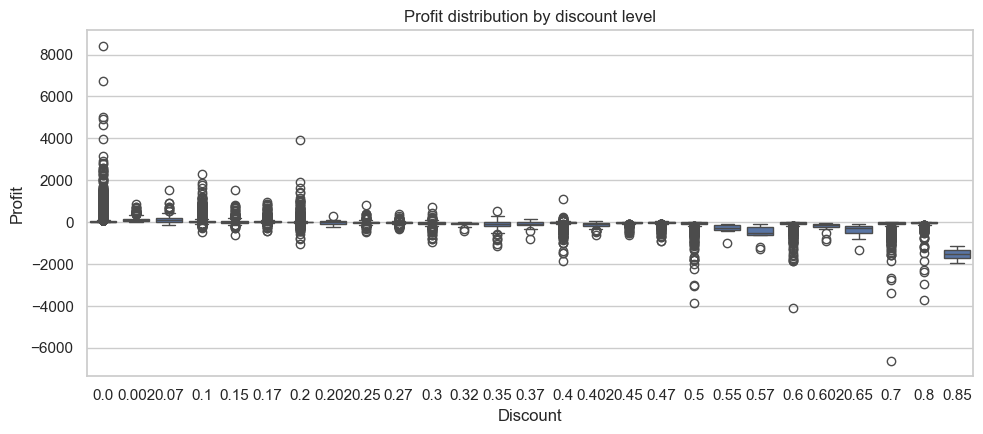

In [17]:
negative_profit_count = int((df["Profit"] < 0).sum())
zero_profit_count = int((df["Profit"] == 0).sum())
positive_profit_count = int((df["Profit"] > 0).sum())
print(f"Negative-profit rows: {negative_profit_count:,}")
print(f"Zero-profit rows: {zero_profit_count:,}")
print(f"Positive-profit rows: {positive_profit_count:,}")

discount_summary = (
    df.groupby("Discount", dropna=False)
      .agg(Rows=("Profit", "size"), Sales=("Sales", "sum"), Profit=("Profit", "sum"),
           Average_Profit=("Profit", "mean"))
      .sort_index()
)
display(discount_summary)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=df, x="Discount", y="Profit", ax=ax)
ax.set_title("Profit distribution by discount level")
plt.tight_layout()
plt.show()


## 13. Findings and questions to resolve

Fill in this section after running the notebook and reviewing the outputs.

### Data-quality findings
- Missing values:
- Date parsing:
- Duplicates and identifier uniqueness:
- Suspicious or unusual numeric values:

### Business findings
- Strongest category by sales:
- Strongest category by profit:
- Lowest-profit sub-categories:
- Leading market/region:
- Monthly or yearly patterns:
- Discount/profit relationship:

### Caveats
- Distinguish genuine business anomalies from data errors.
- Confirm the KPI definitions with the team before dashboard integration.
- Compare the same KPIs and filters against the cleaned dataset later.


## 14. Export a compact baseline summary (optional)

This creates a separate output file in `reports/`; it does not change the raw CSV. Uncomment the lines only when you are ready to save the summary.

In [18]:
# Uncomment to save a baseline KPI CSV after reviewing the results:
# REPORTS_DIR = Path("reports")
# REPORTS_DIR.mkdir(parents=True, exist_ok=True)
# kpi_summary.to_csv(REPORTS_DIR / "raw_eda_baseline_kpis.csv", index=False)
# print("Saved reports/raw_eda_baseline_kpis.csv")
